# 10 · Marketing Mix Modeling contra la verdad

**Sesión 10 · MMM y presupuesto** (ruta Paid Media: MMM, adstock, saturación y optimización de presupuesto).

156 semanas sintéticas de ventas y gasto en 5 canales, generadas con efectos **conocidos** (arrastre, saturación, estacionalidad y una demanda oculta). Dos escenarios: **limpio** (el gasto no mira la demanda) y **endógeno** (se gasta más cuando se espera vender más). Se comparan 4 versiones del MMM y el plan de presupuesto de cada una contra la verdad. `python -m growth_lab.mmm` (≈ 10 min con la robustez); todo se lee de `data/processed/mmm_*`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from growth_lab import db, mmm

plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
P = db.PROCESSED
series = pd.read_parquet(P / "mmm_series.parquet")
roi = pd.read_parquet(P / "mmm_roi.parquet")
err = pd.read_parquet(P / "mmm_error.parquet")
plan = pd.read_parquet(P / "mmm_presupuesto.parquet")
res = pd.read_parquet(P / "mmm_presupuesto_resumen.parquet")
rob = pd.read_parquet(P / "mmm_robustez.parquet")

## 1. Las series: en el escenario endógeno el gasto sigue a la demanda

La demanda oculta (promociones, competencia, clima) mueve las ventas y, en el escenario endógeno, también el gasto. El modelo no la ve: solo ve que cuando se gasta más se vende más.

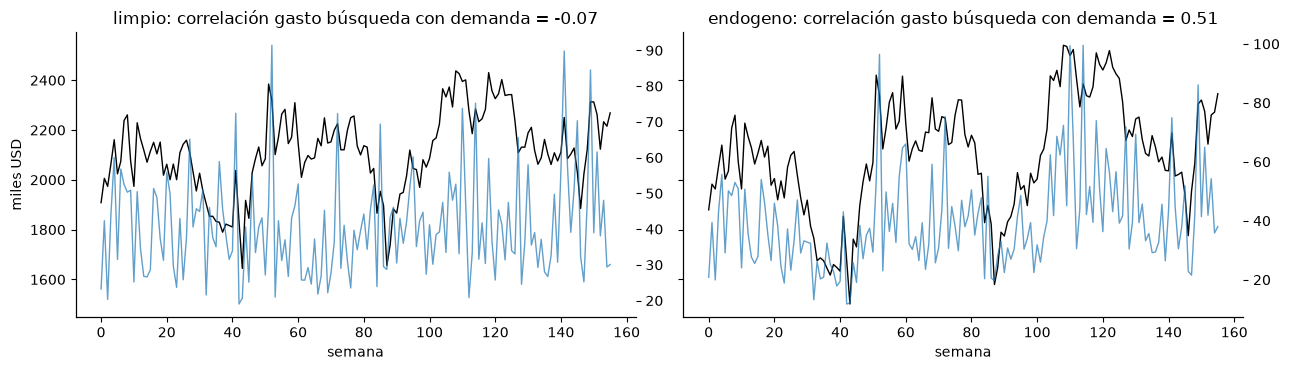

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, esc in zip(axes, ["limpio", "endogeno"]):
    d = series[series.escenario == esc]
    ax.plot(d.semana, d.ventas, color="black", lw=1, label="ventas")
    ax2 = ax.twinx()
    ax2.plot(d.semana, d.gasto_paid_search, color="tab:blue", lw=1, alpha=0.7, label="gasto búsqueda")
    r = np.corrcoef(d.gasto_paid_search, d.verdad_base)[0, 1]
    ax.set_title(f"{esc}: correlación gasto búsqueda con demanda = {r:.2f}")
    ax.set_xlabel("semana")
axes[0].set_ylabel("miles USD")
fig.tight_layout(); fig.savefig("../docs/img/mmm_series.png", dpi=150); plt.show()

## 2. ¿Cuánto se equivoca cada versión? (ROI en ventas por peso pautado)

- **plano:** sin priors. **debil:** priors débiles (arrastre, saturación y ROI). **debil_calibrado:** + experimento de e-mail. **con_control:** + indicador de demanda (tipo Google Trends).

In [3]:
err.round(2)

,escenario,version,mae_roi,error_rel_roi_pct,aporte_medios_verdad_pct,aporte_medios_est_pct,r2
0,limpio,plano,77.31,6367.03,24.50,457.96,0.86
1,limpio,debil,2.03,44.54,24.50,23.13,0.86
2,limpio,debil_calibrado,0.90,29.65,24.50,23.93,0.85
3,limpio,con_control,1.31,45.20,24.50,28.72,0.90
4,endogeno,plano,7.30,167.82,24.08,46.27,0.94
5,endogeno,debil,2.45,91.97,24.08,36.83,0.93
6,endogeno,debil_calibrado,2.12,87.99,24.08,37.10,0.93
7,endogeno,con_control,1.53,52.97,24.08,32.40,0.95


## 3. ROI por canal con el gasto endógeno: con y sin control de demanda

Barras = intervalo del 90% por bootstrap por bloques (incluye el error del experimento de e-mail). El punto negro es la verdad.

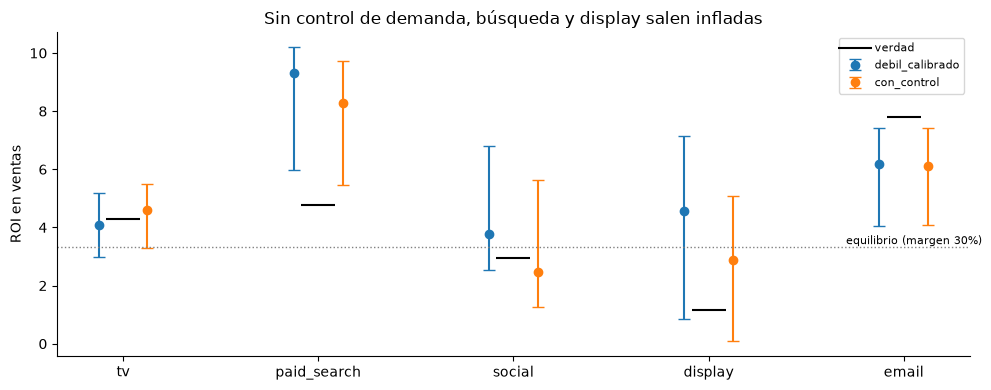

roi_est                 roi_marginal_est                  \
version     con_control debil_calibrado      con_control debil_calibrado   
canal                                                                      
tv                 4.59            4.09             2.73            2.41   
paid_search        8.26            9.31             3.51            3.91   
social             2.47            3.78             1.67            2.51   
display            2.87            4.56             1.85            2.90   
email              6.13            6.18             3.66            3.87   

            roi_marginal_verdad                  roi_verdad                  
version             con_control debil_calibrado con_control debil_calibrado  
canal                                                                        
tv                         2.83            2.83        4.28            4.28  
paid_search                3.02            3.02        4.78            4.78  
social                     1.97            1.97        2.95            2.95  
display                    0.89            0.89        1.16            1.16  
email                      4.53            4.53        7.81            7.81

In [4]:
d = roi[(roi.escenario == "endogeno") & roi.version.isin(["debil_calibrado", "con_control"])]
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(mmm.CANALES))
for k, (v, g) in enumerate(d.groupby("version", sort=False)):
    g = g.set_index("canal").loc[mmm.CANALES]
    ax.errorbar(x + (k - 0.5) * 0.25, g.roi_est, yerr=[g.roi_est - g.roi_p05, g.roi_p95 - g.roi_est],
                fmt="o", capsize=4, label=v)
g = d[d.version == "con_control"].set_index("canal").loc[mmm.CANALES]
ax.scatter(x, g.roi_verdad, color="black", marker="_", s=600, label="verdad", zorder=5)
ax.axhline(1 / mmm.MARGEN, color="grey", ls=":", lw=1)
ax.text(4.4, 1 / mmm.MARGEN, "equilibrio (margen 30%)", fontsize=8, va="bottom", ha="right")
ax.set_xticks(x, mmm.CANALES); ax.set_ylabel("ROI en ventas")
ax.set_title("Sin control de demanda, búsqueda y display salen infladas")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig("../docs/img/mmm_roi.png", dpi=150); plt.show()
d.pivot_table(index="canal", columns="version", values=["roi_verdad", "roi_est", "roi_marginal_verdad", "roi_marginal_est"]).loc[mmm.CANALES].round(2)

## 4. Presupuesto: mismo total, cada canal ±30%

Cada versión del modelo propone un plan; la **ganancia real** se mide con los parámetros verdaderos. La **prometida** es lo que el propio modelo cree que ganará.

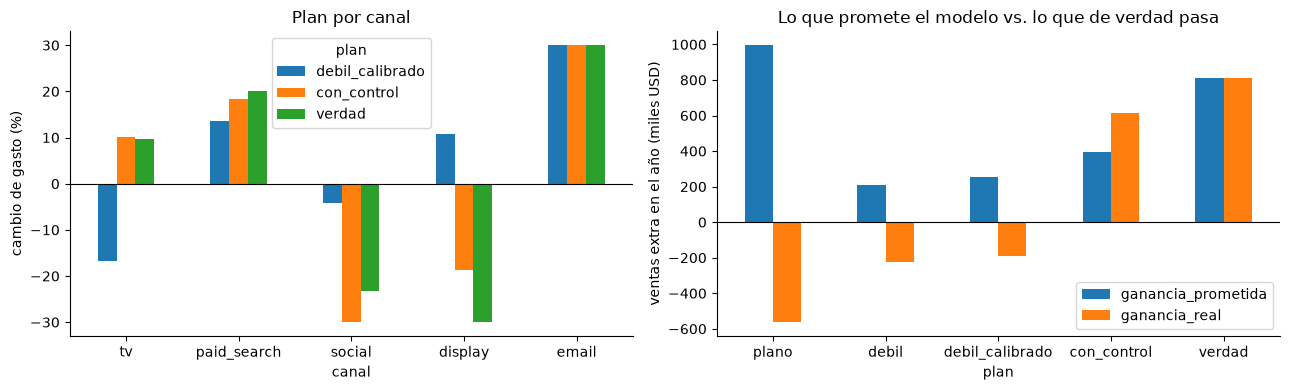

,plan,ganancia_real,ganancia_prometida,gasto_anual,ganancia_real_pct_medios,utilidad_extra
0,plano,-562.8,995.6,8759.6,-1.9,-168.8
1,debil,-221.9,210.7,8759.6,-0.7,-66.6
2,debil_calibrado,-189.0,254.7,8759.6,-0.6,-56.7
3,con_control,612.0,392.8,8759.6,2.0,183.6
4,verdad,808.2,808.2,8759.6,2.7,242.5


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
pv = plan.pivot(index="canal", columns="plan", values="cambio_pct").loc[mmm.CANALES]
pv[["debil_calibrado", "con_control", "verdad"]].plot.bar(ax=axes[0], rot=0)
axes[0].axhline(0, color="black", lw=0.8); axes[0].set_ylabel("cambio de gasto (%)")
axes[0].set_title("Plan por canal")
r = res.set_index("plan")
r[["ganancia_prometida", "ganancia_real"]].plot.bar(ax=axes[1], rot=0)
axes[1].axhline(0, color="black", lw=0.8); axes[1].set_ylabel("ventas extra en el año (miles USD)")
axes[1].set_title("Lo que promete el modelo vs. lo que de verdad pasa")
fig.tight_layout(); fig.savefig("../docs/img/mmm_presupuesto.png", dpi=150); plt.show()
res.round(1)

## 5. Robustez: 10 simulaciones más del escenario endógeno

¿Qué parte de la ganancia óptima captura el plan de cada versión? (100% = el plan perfecto).

In [6]:
pd.concat([rob.groupby("version").captura_pct.describe()[["min", "25%", "50%", "75%", "max"]],
           rob.assign(pierde=rob.ganancia_real < 0).groupby("version").pierde.sum().rename("planes que pierden"),
           rob.groupby("version").mae_roi.median().rename("error ROI (mediana)")], axis=1).loc[mmm.VERSIONES].round(1)

,min,25%,50%,75%,max,planes que pierden,error ROI (mediana)
version,,,,,,,
plano,-141.4,-10.3,3.0,54.3,86.7,5,13.7
debil,-177.3,-28.3,15.2,52.8,62.5,4,2.4
debil_calibrado,-179.5,-9.2,33.8,58.4,80.2,4,2.1
con_control,-1.7,63.3,83.3,93.9,97.7,1,0.7


## Mis conclusiones (Neider)

1. **Sin priors el MMM no sirve:** con 156 semanas se inventa ROI de dos dígitos. Los priors van sobre el ROI, no sobre los coeficientes.
2. **El gasto endógeno engaña:** si gasto más cuando ya iba a vender más, el modelo le da ese mérito a la pauta. Búsqueda salió con ROI 9,3 y display con 4,6 (verdad: 4,8 y 1,2), y el plan prometía +255 mil pero perdía 189 mil.
3. **El indicador de demanda es lo que más ayuda:** el plan pasa a ganar +612 mil de +808 posibles y en 10 simulaciones captura en mediana el 83% del óptimo.
4. **Búsqueda sigue inflada** (8,3 contra 4,8): la subo solo después de una prueba geográfica. Social y display bajan ya; e-mail y TV suben.
5. **Al margen casi nada paga el 30% de margen:** solo e-mail con holgura. Mantengo el total y pruebo un recorte en social y display antes de bajarlo. Display sale sobrevalorado igual que en la atribución de la sesión 9.